# Clasificación con conjunto de datos sobre desinformación
Este cuaderno está basado en el trabajo del artículo ([Oehmichen et al. 2019](https://ieeexplore.ieee.org/document/8819953)), en el que se demuestra que las cuentas de Twitter que crearon y difundieron desinformación en las elecciones presidenciales de EE.UU. en 2016 exhibieron un comportamiento diferente a las cuentas normales. Estos hallazgos sugieren que la _ingenería_ de la desinformación parece explotar rasgos humanos como la reciprocidad y el sesgo de confirmación.

> A. Oehmichen, K. Hua, J. Amador Díaz López, M. Molina-Solana, J. Gómez-Romero and Y. Guo, "Not All Lies Are Equal. A Study Into the Engineering of Political Misinformation in the 2016 US Presidential Election," in IEEE Access, vol. 7, pp. 126305-126314, 2019, doi: [10.1109/ACCESS.2019.2938389](https://ieeexplore.ieee.org/document/8819953).

Los datos completos pueden descargarse de [Zenodo](https://zenodo.org/record/1048826).

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Carga y preprocesamiento de datos

Cargar datos:

In [3]:
data_raw = pd.read_excel('twitter_fakenews_USElections_2016.xlsx')
data_raw.head()

,is_fake_news,tweet_id,created_at,retweet_count,text,user_screen_name,user_verified,user_friends_count,user_followers_count,user_favourites_count,tweet_source,geo_coordinates_available,num_hashtags,num_mentions,num_urls,num_media
0,False,258641295487156224,Wed Oct 17 18:51:04 +0000 2012,1210,@realDonaldTrump YOU SHOULD BE PRESIDENT FOR S...,GHOSTofMEATBALL,False,396,804,91,TweetDeck,0,0,2,0,0
1,False,261135127055327233,Wed Oct 24 16:00:40 +0000 2012,1656,I literally pose half naked for a living and u...,chrissyteigen,True,4024,3983853,20973,Twitter for iPhone,0,0,2,0,0
2,False,264033382076407808,Thu Nov 01 15:57:18 +0000 2012,4688,@realDonaldTrump you are full of shit!,RalphGilles,True,759,29163,3298,Twitter for iPhone,0,0,2,0,0
3,False,265895586660757505,Tue Nov 06 19:17:02 +0000 2012,10418,@realDonaldTrump you're fucking retarded,TimmyWait,False,839,397,506,Twitter Web Client,0,0,2,0,0
4,False,265895723445411841,Tue Nov 06 19:17:35 +0000 2012,1930,@realDonaldTrump You are the stupidest man on ...,mattcale52,False,1184,1350,3364,Twitter for iPhone,0,0,2,0,0


Seleccionar subconjunto de interés:

In [4]:
data = data_raw[data_raw['is_fake_news'] != 'UNKNOWN']

## Análisis exploratorio (copiado del codigo dado en clase)

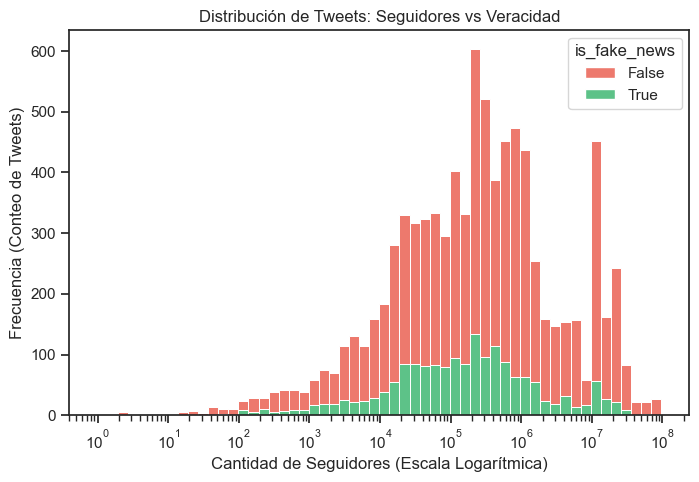

In [5]:
#Definimos el tamaño del lienzo (ancho=8, alto=5 pulgadas)
plt.figure(figsize=(8, 5))

# Configuramos el estilo visual de la gráfica ("ticks" añade pequeñas marcas en los ejes)
sns.set_theme(style="ticks")

# Creamos el histograma con Seaborn
sns.histplot(
    data=data,                           # El DataFrame que contiene la información
    x='user_followers_count',            # Columna para el eje X (cantidad de seguidores)
    hue='is_fake_news',                  # Segmenta las barras por color (Noticia Real vs Fake)
    
    # log_scale=(True, False): Aplica escala logarítmica al eje X pero no al Y.
    # Esto permite ver la distribución de seguidores aunque haya valores muy dispersos.
    log_scale=(True, False), 
    
    # multiple='stack': Apila las categorías del 'hue' una encima de otra en lugar de solaparlas
    multiple='stack', 
    
    # palette: Definimos colores manuales (Rojo para Fake, Verde para Real, por ejemplo)
    palette=sns.color_palette(['#E74C3C', '#27AE60'])
)

# Etiquetas y Títulos
plt.xlabel('Cantidad de Seguidores (Escala Logarítmica)') # Etiqueta del eje X
plt.ylabel('Frecuencia (Conteo de Tweets)')              # Etiqueta del eje Y
plt.title('Distribución de Tweets: Seguidores vs Veracidad') # Título principal

# Comando para renderizar y mostrar la figura en pantalla
plt.show()

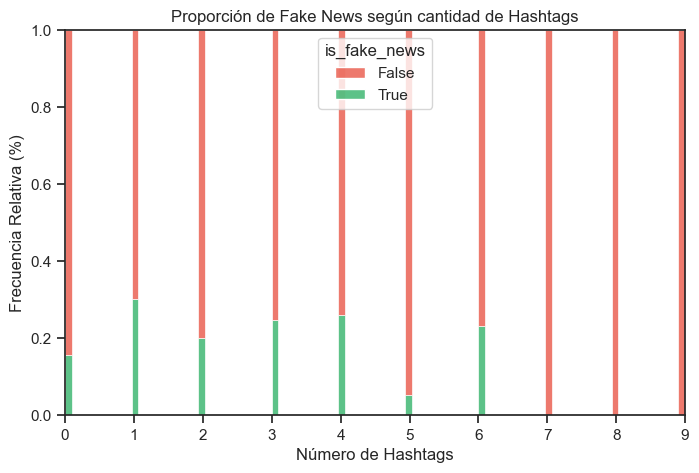

In [6]:
# Configuramos el tamaño de la imagen
plt.figure(figsize=(8, 5))
sns.set_theme(style="ticks")

# Creamos el histograma
sns.histplot(
    data=data,                # El conjunto de datos (DataFrame)
    x='num_hashtags',         # Variable de estudio: cantidad de hashtags por tweet
    hue='is_fake_news',       # Color diferenciado según si es noticia falsa o real
    # Sirve para ver la PROPORCIÓN de cada clase.
    multiple='fill', 
    palette=sns.color_palette(['#E74C3C', '#27AE60'])
)

# Personalización de etiquetas
plt.xlabel('Número de Hashtags')        # Nombre del eje X
plt.ylabel('Frecuencia Relativa (%)')   # El eje Y ahora representa proporción (0 a 1)
plt.title('Proporción de Fake News según cantidad de Hashtags') # Título informativo


plt.show()

## Ejercicio 1: Modelos de clasificación

Entrena, valida y compara dos tipos de modelos de clasificación; por ejemplo, _knn_ frente a _random forest_. Presta atención a la metodología aplicada. Explica las decisiones tomadas y los resultados obtenidos.

Primero, separo la información. Mi variable "y" es lo que quisiera predecir (si es noticia falsa o no) y la X son las características del tweet. Luego, divido todo para tener una parte para entrenar y otra para probar si el modelo aprendió de verdad. Pero yendo por parte, primero es importante limpiar los datos con lo que voy a trabajar

In [7]:
data.info() #para saber los tipos de datos

<class 'pandas.core.frame.DataFrame'>
Index: 8626 entries, 0 to 9000
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   is_fake_news               8626 non-null   object
 1   tweet_id                   8626 non-null   int64 
 2   created_at                 8626 non-null   object
 3   retweet_count              8626 non-null   int64 
 4   text                       8626 non-null   object
 5   user_screen_name           8626 non-null   object
 6   user_verified              8626 non-null   bool  
 7   user_friends_count         8626 non-null   int64 
 8   user_followers_count       8626 non-null   int64 
 9   user_favourites_count      8626 non-null   int64 
 10  tweet_source               8626 non-null   object
 11  geo_coordinates_available  8626 non-null   int64 
 12  num_hashtags               8626 non-null   int64 
 13  num_mentions               8626 non-null   int64 
 14  num_urls     

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# Definición de variables
data['is_fake_news'] = data['is_fake_news'].astype(int)
data['user_verified'] = data['user_verified'].astype(int)

features = ['user_followers_count', 'num_hashtags', 'user_friends_count', 'user_verified']

X = data[features]       # Características
y = data['is_fake_news'] # Objetivo

# División de datos (Train vs Test)
# Separo el 20% para el examen final. 
# random_state=42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Escalado de datos (Crucial para KNN)
# Como KNN mide distancias, si una variable tiene millones (seguidores) y otra tiene unidades (hashtags),
# la de millones va a "aplastar" a la otra. Por eso las pongo en la misma escala.
scaler = StandardScaler()

# El escalador SOLO aprende del set de entrenamiento (fit).
# Al test set solo lo transforma con lo que aprendió del train.
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#Test guardado

C:\Users\tomas\AppData\Local\Temp\ipykernel_14912\2632286207.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['is_fake_news'] = data['is_fake_news'].astype(int)
C:\Users\tomas\AppData\Local\Temp\ipykernel_14912\2632286207.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['user_verified'] = data['user_verified'].astype(int)


Entreno los dos modelos con sus configuraciones, las que vimos en clase

In [9]:

# Modelo A: KNN (k=5 por defecto)
knn_simple = KNeighborsClassifier(n_neighbors=5)
knn_simple.fit(X_train_scaled, y_train)
pred_knn_simple = knn_simple.predict(X_test_scaled)

# Modelo B: Random Forest
rf_simple = RandomForestClassifier(n_estimators=100, random_state=42)
rf_simple.fit(X_train, y_train)
pred_rf_simple = rf_simple.predict(X_test)

# Muestro resultados rápidos
print("KNN:")
print(classification_report(y_test, pred_knn_simple))
print("\nReporte Random Forest:")
print(classification_report(y_test, pred_rf_simple))

KNN:
              precision    recall  f1-score   support

           0       0.83      0.92      0.87      1396
           1       0.36      0.20      0.26       330

    accuracy                           0.78      1726
   macro avg       0.60      0.56      0.56      1726
weighted avg       0.74      0.78      0.75      1726


Reporte Random Forest:
              precision    recall  f1-score   support

           0       0.84      0.87      0.85      1396
           1       0.34      0.28      0.31       330

    accuracy                           0.76      1726
   macro avg       0.59      0.58      0.58      1726
weighted avg       0.74      0.76      0.75      1726



El accurancy esta bien pero el recall no. Hay un desbalance claro de clases. 330 fakes news, sobre 1396 noticas. Ambos modelos son buenos para predecir clase 0, pero muy mal en predecir la clase 1. Esto es necesario corregirlo. (ver recall bajo). Por mas bueno que sea el accurancy, necesitamos que el recall aumente ya que queremos que prediga la clase 1

Intento probar otros K, para ver si mejora. Hay que hacerlo sobre los datos de entrenameinto. 
Pero decidi plicar dos mejoras:
Cross-Validation: Para elegir el hiperparámetro K del KNN.  Así elijo el mejor K sin tocar el Test Set.
Balanceo de Clases (class_weight): En el Random Forest, le ordené al algoritmo que penalice más fuerte los errores en las Fake News. Esto obliga al modelo a prestar atención a la clase minoritaria, aver si a partir de aca mejora los resultados del modelo.


In [10]:
# KNN con selección de parámetros con CV

k_range = range(1, 20) # Probaré del 1 al 19 vecinos
k_scores = []


for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='accuracy')
    k_scores.append(scores.mean())

# Selecciono el K que dio mejor resultado promedio
best_k = k_range[k_scores.index(max(k_scores))]
print(f"-> Decisión tomada: El valor óptimo validado es K={best_k}")

# Entreno el modelo KNN FINAL con ese K ganador
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train_scaled, y_train)


# ---------------------------------------------------------
# Random Forest

# Decisión: Agrego class_weight='balanced'.
# Esto equilibra la balanza: equivocarse en una Fake News costará más caro.
rf_final = RandomForestClassifier(
    n_estimators=100, 
    class_weight='balanced',  #La clave para mejorar el Recall
    random_state=42
)

rf_final.fit(X_train, y_train)

-> Decisión tomada: El valor óptimo validado es K=12


RandomForestClassifier(class_weight='balanced', random_state=42)

In [11]:
print(f"1. KNN Optimizado (K={best_k}):")
pred_knn_final = knn_final.predict(X_test_scaled)
print(classification_report(y_test, pred_knn_final))

print("2. Random Forest (Balanceado):")
pred_rf_final = rf_final.predict(X_test)
print(classification_report(y_test, pred_rf_final))

1. KNN Optimizado (K=12):
              precision    recall  f1-score   support

           0       0.82      0.96      0.89      1396
           1       0.43      0.14      0.21       330

    accuracy                           0.80      1726
   macro avg       0.63      0.55      0.55      1726
weighted avg       0.75      0.80      0.76      1726

2. Random Forest (Balanceado):
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1396
           1       0.34      0.27      0.30       330

    accuracy                           0.76      1726
   macro avg       0.59      0.58      0.58      1726
weighted avg       0.74      0.76      0.75      1726



No me convencen los resultados


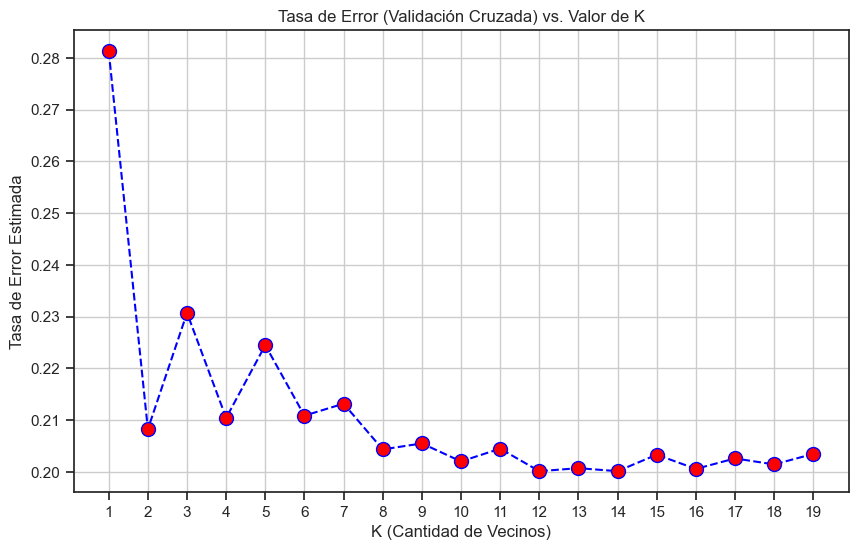

El gráfico me indica que el error más bajo se consigue con K = 12


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score

#ANÁLISIS VISUAL DE HIPERPARÁMETROS

# Decisión: Quiero ver gráficamente cómo se comporta el error al cambiar K.
# Usaré el error promedio de la Validación Cruzada

tasa_error = []
rango_k = range(1, 20) # Pruebo del 1 al 19

for i in rango_k:
    knn = KNeighborsClassifier(n_neighbors=i)
    
    # IMPORTANTE: Aquí uso cross_val_score.
    # Esto divide el Train en 5 partes, entrena en 4 y valida en 1.
    # El 'score' es la exactitud (accuracy)
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='accuracy')
    
    # Guardo el promedio de error de los 5 simulacros
    tasa_error.append(1 - scores.mean())

# Grafico los resultados
plt.figure(figsize=(10, 6))
plt.plot(rango_k, tasa_error, color='blue', linestyle='dashed', marker='o',
         markerfacecolor='red', markersize=10)
plt.title('Tasa de Error (Validación Cruzada) vs. Valor de K')
plt.xlabel('K (Cantidad de Vecinos)')
plt.ylabel('Tasa de Error Estimada')
plt.xticks(rango_k) # Para ver todos los números en el eje X
plt.grid(True)
plt.show()

# Busco visualmente (y por código) el punto más bajo
mejor_k_visual = rango_k[tasa_error.index(min(tasa_error))]
print(f"El gráfico me indica que el error más bajo se consigue con K = {mejor_k_visual}")

Creo que el KNN no es el mejor modelo para el data set, ya que el grafico confirma que k=12 es el mejor parAMETRO, lo que confirma el CV. Ajustaremos Random Forest y prestare atencion al recall, porque los datos estan desbalanceados.


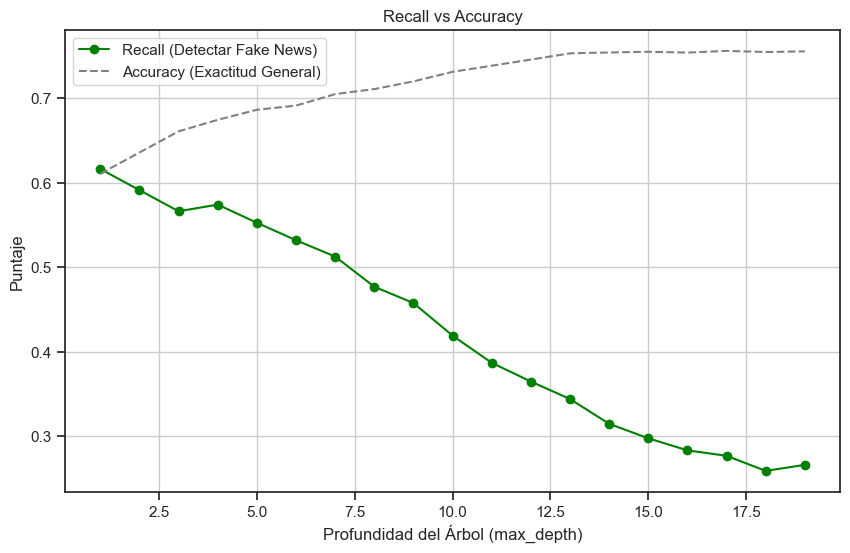

-> Según la validación, la mejor profundidad para detectar Fake News es: 1

REPORTE FINAL DEL MODELO
              precision    recall  f1-score   support

           0       0.86      0.59      0.70      1396
           1       0.26      0.61      0.36       330

    accuracy                           0.60      1726
   macro avg       0.56      0.60      0.53      1726
weighted avg       0.75      0.60      0.64      1726



In [13]:
# RANDOM FOREST

# Rango de profundidades a probar
depths = range(1, 20) 

# Listas para guardar los resultados
recall_scores = []
accuracy_scores = []

for d in depths:
    # Configuro el modelo con BALANCEO DE CLASES
    rf = RandomForestClassifier(n_estimators=100, 
                                max_depth=d, 
                                class_weight='balanced', 
                                random_state=42)
    
    # --- VALIDACIÓN CRUZADA ---
    # Aca está el cambio clave metodológico: scoring='recall'
    # Le pido que mida qué tan bueno es encontrando la clase "1" (Fake News)
    scores_rec = cross_val_score(rf, X_train, y_train, cv=5, scoring='recall')
    scores_acc = cross_val_score(rf, X_train, y_train, cv=5, scoring='accuracy')
    
    recall_scores.append(scores_rec.mean())
    accuracy_scores.append(scores_acc.mean())

#  GRAFICAMOS
plt.figure(figsize=(10, 6))
plt.plot(depths, recall_scores, label='Recall (Detectar Fake News)', color='green', marker='o')
plt.plot(depths, accuracy_scores, label='Accuracy (Exactitud General)', color='gray', linestyle='--')
plt.title('Recall vs Accuracy')
plt.xlabel('Profundidad del Árbol (max_depth)')
plt.ylabel('Puntaje')
plt.legend()
plt.grid(True)
plt.show()

# Selecciono la profundidad que dio el MEJOR RECALL
best_depth = depths[recall_scores.index(max(recall_scores))]
print(f"-> Según la validación, la mejor profundidad para detectar Fake News es: {best_depth}")

# ENTRENAMIENTO
rf_final = RandomForestClassifier(n_estimators=100, 
                                  max_depth=best_depth, 
                                  class_weight='balanced', 
                                  random_state=42)
rf_final.fit(X_train, y_train)

# Evaluación
print("\nREPORTE FINAL DEL MODELO")
print(classification_report(y_test, rf_final.predict(X_test)))

Se observa una mejora sustancial en el objetivo. Aunque Accuracy disminuyó al 0.60, el modelo ha logrado detectar noticias falsas.

Análisis de mejora: En el primer intento, el Recall era de apenas 0.28 (detectábamos unas 93 noticias falsas y perdíamos el resto). Tras la optimización de hiperparámetros y el balanceo de clases, el Recall subió a 0.61.
La validación cruzada indicó que una profundidad muy baja (max_depth=1) junto con el balanceo de pesos (class_weight='balanced') esla configuración ideal. 

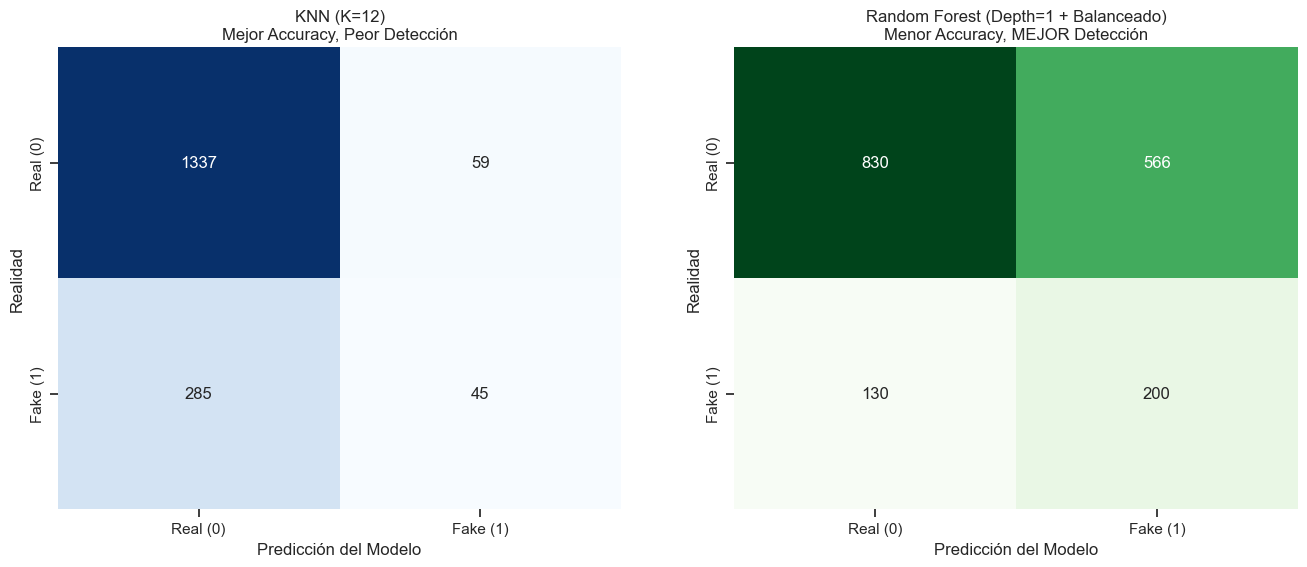

In [14]:
from sklearn.metrics import confusion_matrix

# Genero las predicciones finales con los modelos que ya entrenamos
pred_knn = knn_final.predict(X_test_scaled)
pred_rf = rf_final.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
clases = ['Real (0)', 'Fake (1)']

# --- MATRIZ 1: KNN ---
cm_knn = confusion_matrix(y_test, pred_knn)
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=clases, yticklabels=clases, cbar=False)
axes[0].set_title(f'KNN (K={best_k})\nMejor Accuracy, Peor Detección')
axes[0].set_xlabel('Predicción del Modelo')
axes[0].set_ylabel('Realidad')

# --- MATRIZ 2: Random Forest (El modelo elegido) ---
cm_rf = confusion_matrix(y_test, pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=clases, yticklabels=clases, cbar=False)
axes[1].set_title(f'Random Forest (Depth={best_depth} + Balanceado)\nMenor Accuracy, MEJOR Detección')
axes[1].set_xlabel('Predicción del Modelo')
axes[1].set_ylabel('Realidad')

plt.show()

### Conclusiones
Siguiendo una metodología de validación cruzada, el gráfico de *Trade-off* me enseñó que buscar la mayor *Accuracy* era un error: el modelo KNN tenía buena nota general, pero la Matriz de Confusión demostró que no era bueno detectando fakes news.

Por eso, mi elección final es el **Random Forest balanceado** (con profundidad 1). Aunque genera más falsas alarmas, logramos subir el *Recall* al 61%. Aumentar la complejidad del modelo (profundidad) solo servía para memorizar noticias reales, sacrificando la capacidad de detectar las falsas.

## Ejercicio 2: Redes neuronales
Extiende el ejercicio anterior utilizando un modelo de clasificación de redes neuronales.

Al igual que en KNN necesitamos normalizar y escalar los datos
Ya tenemos X_train_scaled y X_test_scaled del ejercicio anterior, por lo tanto los vamos a volver a usar. en este sentido, vamos reciclando lo que ya hicimos antes

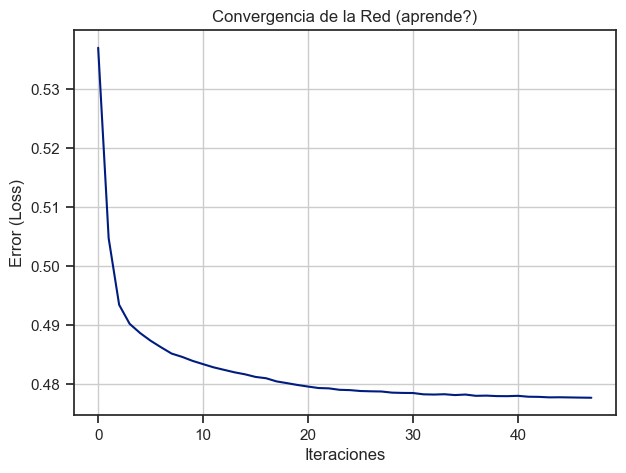

In [15]:
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV

# Configuración inicial simple (2 capas de 10 neuronas, 10,10)
# max_iter=1000 es importante para darle tiempo a aprender (esto es porque mientra mas iteraciones mas tiempo se le da para aprender)
mlp_basico = MLPClassifier(hidden_layer_sizes=(10, 10), max_iter=1000, random_state=42)
mlp_basico.fit(X_train_scaled, y_train)

# Graficamos la curva de aprendizaje
plt.figure(figsize=(7, 5))
sns.set_theme(style="ticks", palette="dark")
# loss_curve_ guarda el historial de errores paso a paso
sns.lineplot(data=mlp_basico.loss_curve_)
plt.title('Convergencia de la Red (aprende?)')
plt.xlabel('Iteraciones')
plt.ylabel('Error (Loss)')
plt.grid(True)
plt.show()

La línea baja y se aplana conforme baja el valor, significa que la red entendió algo. El error se estabiliza en 0.47 aproximadamente y a partir de 30 iteraciones. 

Paso al GridSearchCV. Será util para probar la mejor combinación y evitar hacerlo manual.
DEbido a la experiencia previa con KNN y Random Forest, sabemos que la accuracy es engañoso para este dataset. Así que voy a cambiar scoring a 'recall' en el GridSearch, ya que el objetivo es obtener las fake news.

In [16]:
# Búsqueda de Hiperparámetros (GridSearch)
param_grid = {
    'hidden_layer_sizes': [(10,), (50,), (10, 10), (50, 50)], # Probamos redes simples y profundas
    'activation': ['relu', 'tanh'],  # Formas de "pensar" de la neurona
    'alpha': [0.0001, 0.01, 0.1],    # Regularización (Castigo para evitar memorizar)
    'solver': ['adam'],              # El optimizador estándar que funciona bien
    'learning_rate': ['constant', 'adaptive']
}

# scoring='recall'
grid_search = GridSearchCV(
    estimator=MLPClassifier(max_iter=2000, random_state=42),
    param_grid=param_grid,
    scoring='recall',  
    cv=5,              # 5 Validaciones cruzadas
    n_jobs=-1          # Usa todos los núcleos de la compu para ir más rápido
)

grid_search.fit(X_train_scaled, y_train)

print(f"Mejor configuración encontrada: {grid_search.best_params_}")
print(f"Mejor Recall en Validación: {grid_search.best_score_:.2f}")

Mejor configuración encontrada: {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (10, 10), 'learning_rate': 'constant', 'solver': 'adam'}
Mejor Recall en Validación: 0.00


GridSearchCV eligió el mejor ajuste, ahora probamos contra el Test Set y miramos la Matriz de Confusión, tal como hicimos con el Random Forest.

              precision    recall  f1-score   support

           0       0.81      1.00      0.89      1396
           1       0.00      0.00      0.00       330

    accuracy                           0.81      1726
   macro avg       0.40      0.50      0.45      1726
weighted avg       0.65      0.81      0.72      1726



c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


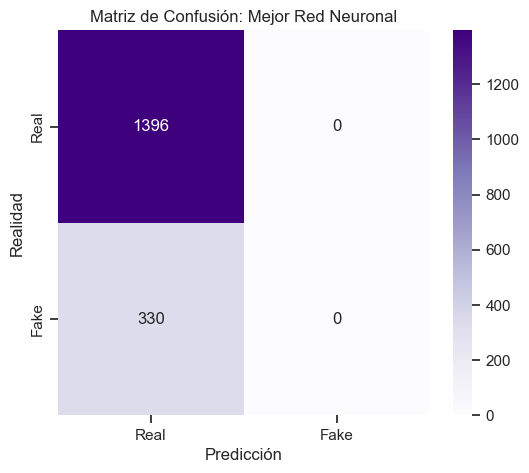

In [17]:
from sklearn.metrics import classification_report, confusion_matrix

# Recupero el mejor modelo
mejor_red = grid_search.best_estimator_

# Predicción final sobre el TEST set
pred_red = mejor_red.predict(X_test_scaled)


print(classification_report(y_test, pred_red))

# Matriz de Confusión Visual
cm_nn = confusion_matrix(y_test, pred_red)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_nn, annot=True, fmt='d', cmap='Purples', 
            xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'])
plt.title('Matriz de Confusión: Mejor Red Neuronal')
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.show()

No nos dio resultado. Probaremos con un ajuste manual porque parece que es la consencuncia es que los datos estan desbalanceados.
Vamos a "penalizar", digamos si hay alguna sospecha lo marcaremos como fake.

AUC Score del modelo: 0.626
--- REPORTE CON UMBRAL AJUSTADO (0.15) ---
              precision    recall  f1-score   support

           0       0.87      0.53      0.66      1396
           1       0.25      0.67      0.37       330

    accuracy                           0.56      1726
   macro avg       0.56      0.60      0.51      1726
weighted avg       0.75      0.56      0.60      1726



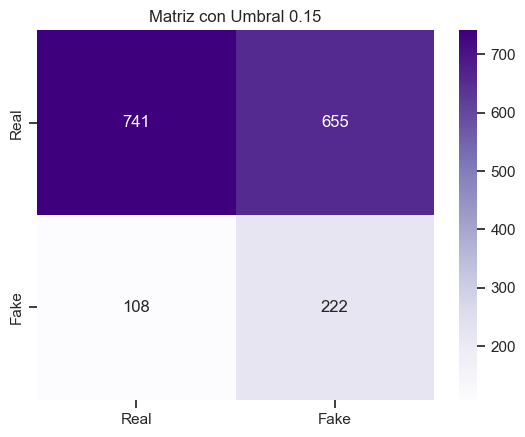

In [18]:
from sklearn.metrics import classification_report, roc_auc_score
import numpy as np

# Recuperamos el mejor modelo que encontró el GridSearch
best_nn = grid_search.best_estimator_

# En vez de predict(), usamos predict_proba()
# Esto nos da la probabilidad (de 0 a 1) de que sea Fake News
probs_test = best_nn.predict_proba(X_test_scaled)[:, 1]

# AUC Score
auc = roc_auc_score(y_test, probs_test)
print(f"AUC Score del modelo: {auc:.3f}")

# BAJAMOS Umbral
umbral = 0.15

pred_ajustada = (probs_test > umbral).astype(int)

print(f"--- REPORTE CON UMBRAL AJUSTADO ({umbral}) ---")
print(classification_report(y_test, pred_ajustada))

# Matriz de confusión rápida
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, pred_ajustada)
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'])
plt.title(f'Matriz con Umbral {umbral}')
plt.show()

EL recall ha aumentado hasta llegar al 67%, es un numero optimo teniendo en cuenta que representan 222 verderos positivo (fakes). Si comparamos con el random forest, este obtuvo 61%, es decir que se ha superado al modelo anterior. Sin embargo hayq que tener en cuenta que el modelo tomo 655 noticias como fake que eran verdaderas, esto es por el ajuste que realizamos en el codigo donde el modelo, ante una duda, marca como fake. Teniendo en cuenta que el accurancy bajo (56%) he optado revisar mas de 600 noticias reales por error, antes que dejar que se me escapen las Fake News que es el objetivo. El ajuste manual tuvo resultados positivos. 

Bajar el umbral y captar mas fake, fue suerte? intentaré responder con la curva ROC que me mostrará todos los umbrales posibles y la capacidad discriminatoria del modelo. 

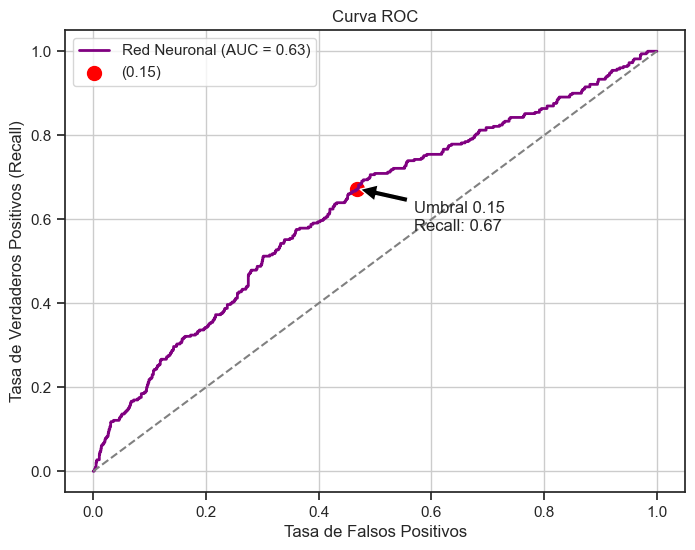

In [19]:
from sklearn.metrics import roc_curve, roc_auc_score

#CURVA ROC

# Calculamos los puntos de la curva usando las probabilidades que ya tengo
fpr, tpr, thresholds = roc_curve(y_test, probs_test)
auc_score = roc_auc_score(y_test, probs_test)

plt.figure(figsize=(8, 6))

# Graficamos la curva del modelo
plt.plot(fpr, tpr, color='purple', label=f'Red Neuronal (AUC = {auc_score:.2f})', linewidth=2)

plt.plot([0, 1], [0, 1], color='gray', linestyle='--')


# Buscamos el punto en la curva más cercano al umbral de 0.15
cercano_idx = np.argmin(np.abs(thresholds - 0.15))
plt.scatter(fpr[cercano_idx], tpr[cercano_idx], s=100, c='red', label='(0.15)')
plt.annotate(f'Umbral 0.15\nRecall: {tpr[cercano_idx]:.2f}', 
             (fpr[cercano_idx], tpr[cercano_idx]), 
             xytext=(fpr[cercano_idx]+0.1, tpr[cercano_idx]-0.1),
             arrowprops=dict(facecolor='black', shrink=0.05))

plt.title('Curva ROC')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos (Recall)')
plt.legend()
plt.grid(True)
plt.show()

El grafico muestra que mi modelo es debil a la hora de detectar fakes, aunque es el mejor umbral que encontré no es lo óptimo. A la red neuronal le costo mucho encontrar patrones claros pero además esta metiendo bajo sospecha a un monton de noticias verdaderas. 
Con este grafico curva ROC podemos ver que si bien hemos obtenido un buen recall, random forest mantuvo menos nivel de equivocación con las noticias reales. 

In [ ]:
param_grid_final = {
    'hidden_layer_sizes': [(50, 25), (100, 50), (100,)], 
    # 'tanh' y 'relu'
    'activation': ['relu', 'tanh'],
    # Probamos SGD además de Adam
    'solver': ['adam', 'sgd'],
    # Probamos regularización más fuerte para limpiar ruido
    'alpha': [0.0001, 0.05],
    # Tasa de aprendizaje
    'learning_rate': ['adaptive'] 
}

grid_search_final = GridSearchCV(
    # Le damos muchas iteraciones (max_iter=3000)
    estimator=MLPClassifier(max_iter=3000, random_state=42), 
    param_grid=param_grid_final,
    scoring='roc_auc',  # Bscamos maximizar el AUC, no solo Recall
    cv=3,               
    n_jobs=-1
)

grid_search_final.fit(X_train_scaled, y_train)

print(f"Mejor configuración FINAL: {grid_search_final.best_params_}")


best_nn_final = grid_search_final.best_estimator_
probs_final = best_nn_final.predict_proba(X_test_scaled)[:, 1]
auc_final = roc_auc_score(y_test, probs_final)

print(f"\nAUC Intento anterior: 0.63")
print(f"AUC Nuevo:     {auc_final:.3f}")

if auc_final > 0.63:
    print("actualizar el gráfico ROC.")
else:
    print("No hubo mejora significativa.")

Mejor configuración FINAL: {'activation': 'relu', 'alpha': 0.05, 'hidden_layer_sizes': (100, 50), 'learning_rate': 'adaptive', 'solver': 'adam'}

AUC Intento anterior: 0.63
AUC Nuevo:     0.622
No hubo mejora significativa.


### Conclusiones
Resume en menos de 100 palabras las principales conclusiones del estudio.

El analisis de datos llevado a cabo refleja que la red neuronal tuvo una capacidad discriminatoria moderada, es decir, no hay una separación limpia de las clases, lo que genero que el modelo se aprenda muy bien los fake a costa de distinguir muchas noticias reales como sospechosas. En si no es negativo, pero podemos ver que en el random forest ha sido mas eficiente, el recall es menor, pero el accurancy es mayor. En ultima instancia depende mucho del objetivo del trabajo, en nuestro caso, creo que es mas optimo la red neuronal porque es capaz de captar mas fake sin embargo el random forest es mas eficiente. Por ultimo, se realizó una busqueda exhaustiva de hiperparametros con GridSearch, pero no se pudo aumentar el AUC, por lo que entendemos que el modelo llego al limite. 